# Statistics analysis

In [0]:
using DmspElfinConjunction, DMSP
using Dates
using TimeseriesUtilities
using DimensionalData, DataFrames, DataFramesMeta
using GeoCotrans
using Accessors
using AlgebraOfGraphics
using CairoMakie
!haskey(ENV, "VSCODE_GIT_ASKPASS_NODE") && using GLMakie
using StatsBase
using CategoricalArrays
using Beforerr: easy_save

includet("../src/plot.jl")
includet("../src/workload.jl")
includet("../src/mechanisms.jl")
includet("../src/statplot.jl")
include("../src/statplot.jl")
includet("../src/demo.jl")
includet("../src/analysis.jl")

In [0]:
using SpectralModels: A, κ, E_c, n_flux, e_flux

const γ_len = @optic _.γ
const m1 = @optic _.model1
const m2 = @optic _.model2
const Emin = @optic _.Emin

let df = df, rev = false
    qs = (x -> round.(quantile(skipmissing(x), [0.02, 0.1, 0.9, 0.98]), sigdigits=2)) => :quantiles
    vals = A.(m1.(df.model))
    @info describe(parameters(df), :mean, qs, :q25, :median, :q75, :nmissing)
end

sdf = let Emin = 0.03
    @chain parameters(df) begin
        @rsubset!(20 > :κ > 1, :E_c1 < 20, :E_c2 < 20, abs(:γ) < 20, 0 < :log_A1 < 30, 0 < :log_A2 < 20)
        integrate_flux!(Emin)
    end
end

bin(x, δx) = (x + δx / 2) - (x + δx / 2) % δx
demlt(x::T) where T = x == 24 ? zero(T) : x
fmt(from, to, i; leftclosed, rightclosed) = from + (to - from) / 2

cut_AE(df; breaks=[0, 100, 300]) = @transform(df, :maxAE_bin = cut(:maxAE, breaks; extend=true))

# Prepare data with MLT and MLAT binning
make_gdf(df; mlat_binedges=52.5:1:80.5, Δmlt=1) = @chain df begin
    cut_AE
    @transform(
        :mlt_bin = demlt.(bin.(mlt_mean.(:mlt_elx, :mlt_dmsp), Δmlt)),
        :mlat_bin = Array(cut(abs.(:mlat), mlat_binedges; extend=missing, labels=fmt)),
    )
    @groupby(:mlt_bin, :mlat_bin, :maxAE_bin)
end

gdf = make_gdf(sdf)

size(sdf, 1) # 28739

## Check some events

In [0]:
begin
    #  find a good example for demostration purpose in the sense overlapping time,mlt and mlat at the same time
    row = @rsubset(sdf, :Δt < Millisecond(100000), :Δmlt < 0.1)[75, :]

    # row = tdf[2, :]
    probe = row.elfin
    trange = extend(row.trange_elx, Minute(4))
    elx_mlt_trange = extend(trange, Second(1)) # Extend a bit to cover flux time range
    @info probe row.id, trange row.mlat
    elx_flux = permutedims(ELFIN.epd(trange, probe))
    elx_gei = ELFIN.gei(elx_mlt_trange, probe)
    elx_mlt, elx_mlat = gei2mlt_mlat(tview(elx_gei, elx_mlt_trange))

    dmsp_mlt, dmsp_mlat = get_mlt_mlat(row.id, trange)
    dmsp_flux = DMSP.flux(trange, row.id)

    tdf = workload(trange, (row.id,), elx_flux, elx_gei)
    mlats = nothing
    # mlats = -66:0.5:-65

    # quicklook(trange, elx_flux, elx_mlt, elx_mlat, dmsp_flux, dmsp_mlt, dmsp_mlat)
    f = Figure(; size=(800, 600))
    # TODO: update
    demo_plot(f, trange, tdf, elx_flux, elx_mlt, elx_mlat, dmsp_flux, dmsp_mlt, dmsp_mlat; mlats, add_ratios=false, colormap=:batlow)
    f
end

### Multiple peaks in kappa distribution

Related to ([**fig-param-pdf?**](#ref-fig-param-pdf)). Three examples of electron flux spectra.

In [0]:
# Find examples with kappa ≈ 2, 5, 8 for AE > 300, MLAT > 65, and 0 < MLT < 9
target_kappas = [2, 5, 8]

example_df = @chain sdf begin
    @rsubset(:maxAE > 300, abs(:mlat) > 65, :mlt_elx < 9)
    @transform(:kappa_diff = abs.(:κ .- 2))  # Start with first target
end

# Find one example for each target kappa
examples = map(target_kappas) do target_κ
    @chain example_df begin
        @transform(:kappa_diff = abs.(:κ .- target_κ))
        @orderby(:kappa_diff)
        first
    end
end
# Create figure with 3 panels showing the spectra
let f = Figure(size=(1200, 400))
    axs = map(enumerate(examples)) do (i, row)
        title = "κ = $(round(row.κ, digits=1)), MLAT = $(round(row.mlat, digits=1))°, MLT = $(round(row.mlt_elx, digits=1))"
        ax = Axis(f[1, i]; xlabel=𝒀.E, ylabel=𝒀.nflux, xscale=log10, yscale=log10, title)

        scatterlines!(ax, row.flux_dmsp; label="DMSP")
        scatterlines!(ax, row.flux_elx; label="ELFIN")
        energies = vcat(row.flux_dmsp.dims[1].val, row.flux_elx.dims[1].val)
        lines!(ax, energies, row.model.(energies); label="Model", linewidth=2, color=:red)
        # Add transition energy line
        vlines!(ax, row.Emin; color=:grey, linestyle=:dash, label="E_tran")
        ax
    end
    axislegend(axs[1]; position=:lb)
    hideydecorations!.(axs[2:3]; grid=false)
    ylims!.(axs, 5, 5e11)
    linkaxes!(axs...)
    # easy_save("kappa_examples")
    f
end

## Dependence analysis

In [0]:
using Statistics

vars = [:log_A1 => "Log A (ExpPow)", :E_c1 => "E_c (ExpPow)", :γ => "γ (ExpPow)", :Emin => "Transition Energy", :log_A2 => "Log A (Kappa)", :E_c2 => "E_c (Kappa)", :κ => "κ (Kappa)"]

### MLT, maxAE space

In [0]:
tdf = let binedges_ae = [0, 100, 300], binedges_mlt = 0:2:24
    @chain sdf begin
        @transform(
            :maxAE_bin = cut(:maxAE, binedges_ae; extend=true),
            :mlt_bin = cut(:mlt_elx, binedges_mlt; extend=missing, labels=mlt_fmt),
        )
        @groupby(:mlt_bin, :maxAE_bin)
        combine(_variable.(vars) .=> mean, renamecols=false)
        dropmissing!
    end
end

#  plot in such a way, that it will be MLT from 12 to 24, and then from 0 to 12, so 24=0 will be in the middle of figure
f = Figure(; size=(600, 600))
base_plt = data(tdf) * mapping(:mlt_bin => "MLT", :maxAE_bin => "AE") * visual(Heatmap)
layouts = [(1, 1), (2, 1), (3, 1), (1, 2), (2, 2), (3, 2)]
foreach(layouts, vars) do (i, j), var
    gl = GridLayout(f[i, j])
    sf = draw!(gl[2, 1], base_plt * mapping(var))
    colorbar!(gl[1, 1], sf; vertical=:false)
    i != 3 && hidexdecorations!(sf[1].axis)
    j != 1 && hideydecorations!(sf[1].axis)
    rowgap!(gl, 4)
end
easy_save("params_mlt_ae_mean")

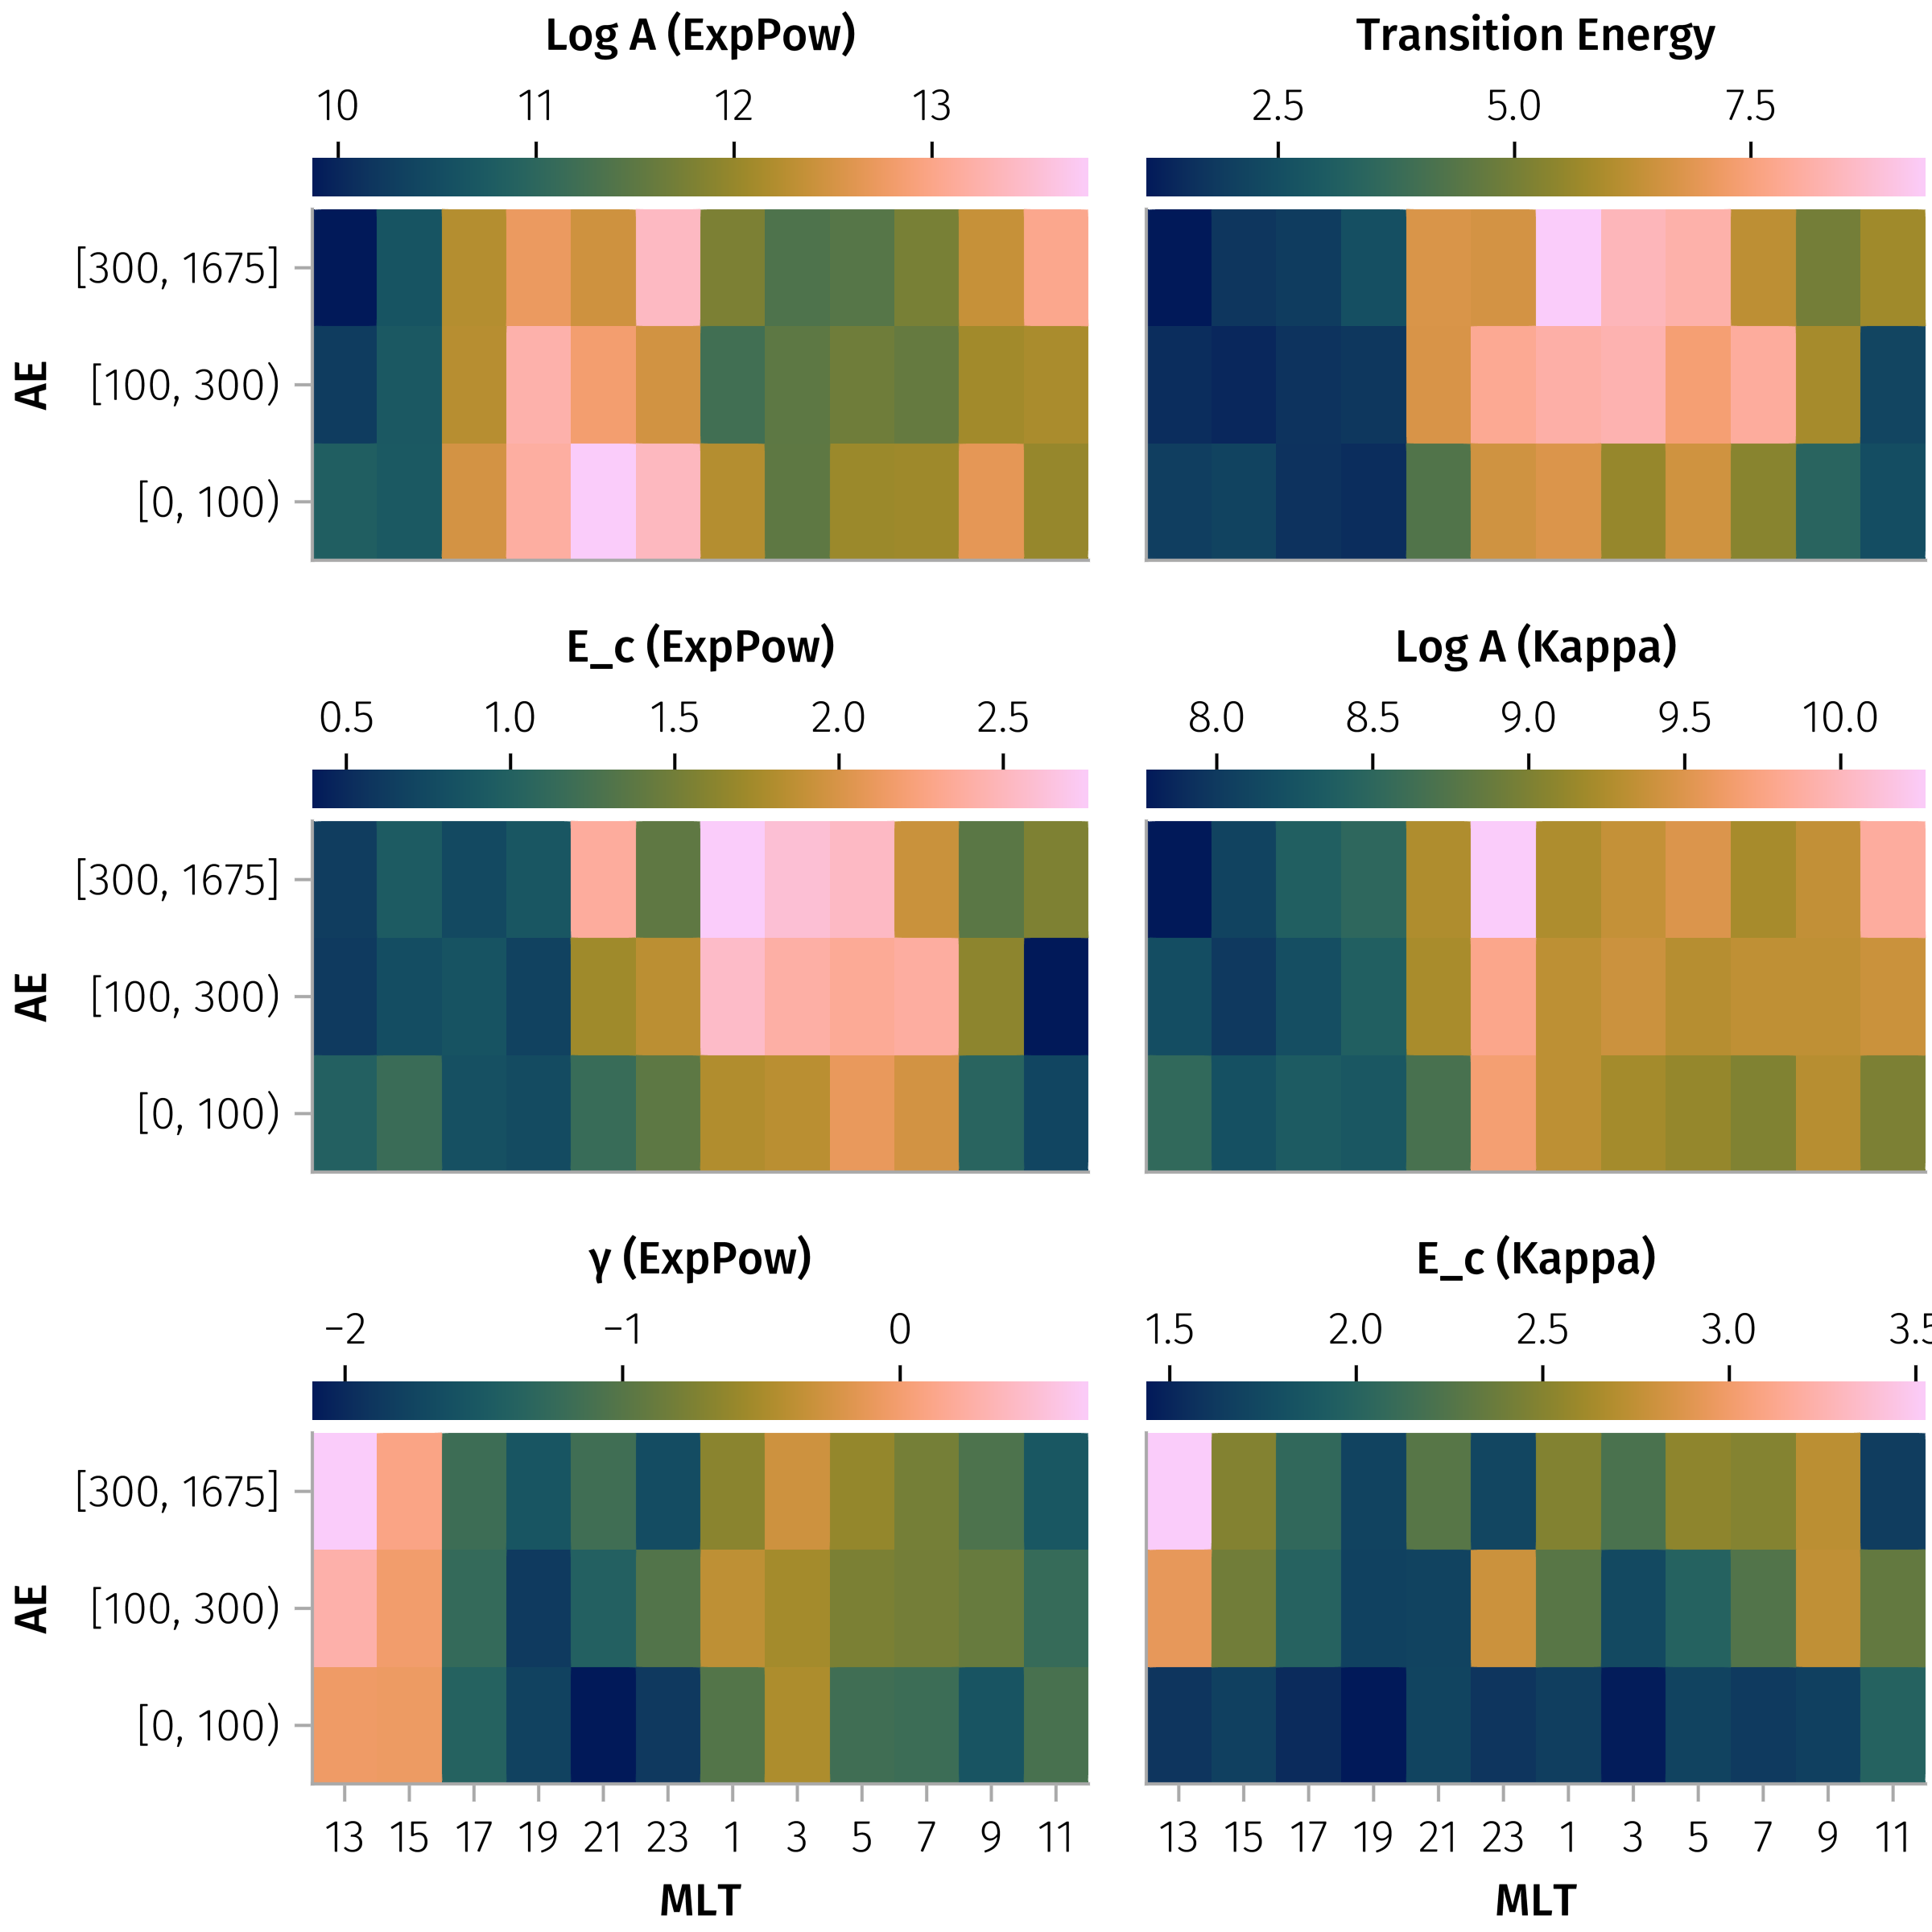

## MLT, MLAT space, separately for three MaxAE ranges

In [0]:
const m2axis = (; xtickformat=mlt_tickformat, xticks=0:3:24)
f = let df = combine(gdf, nrow => :n, renamecols=false) |> dropmissing!
    plt = data(df) * mapping(:mlt_bin => mlt2x => "MLT", :mlat_bin => "MLAT", :n) * visual(Heatmap) * mapping(col=:maxAE_bin)
    fg = draw(plt; figure=(; size=(1000, 300)), axis=m2axis)
    fg.grid[1].axis.yticks[] = 53:3:80
    easy_save("n_mlt_mlat")
end

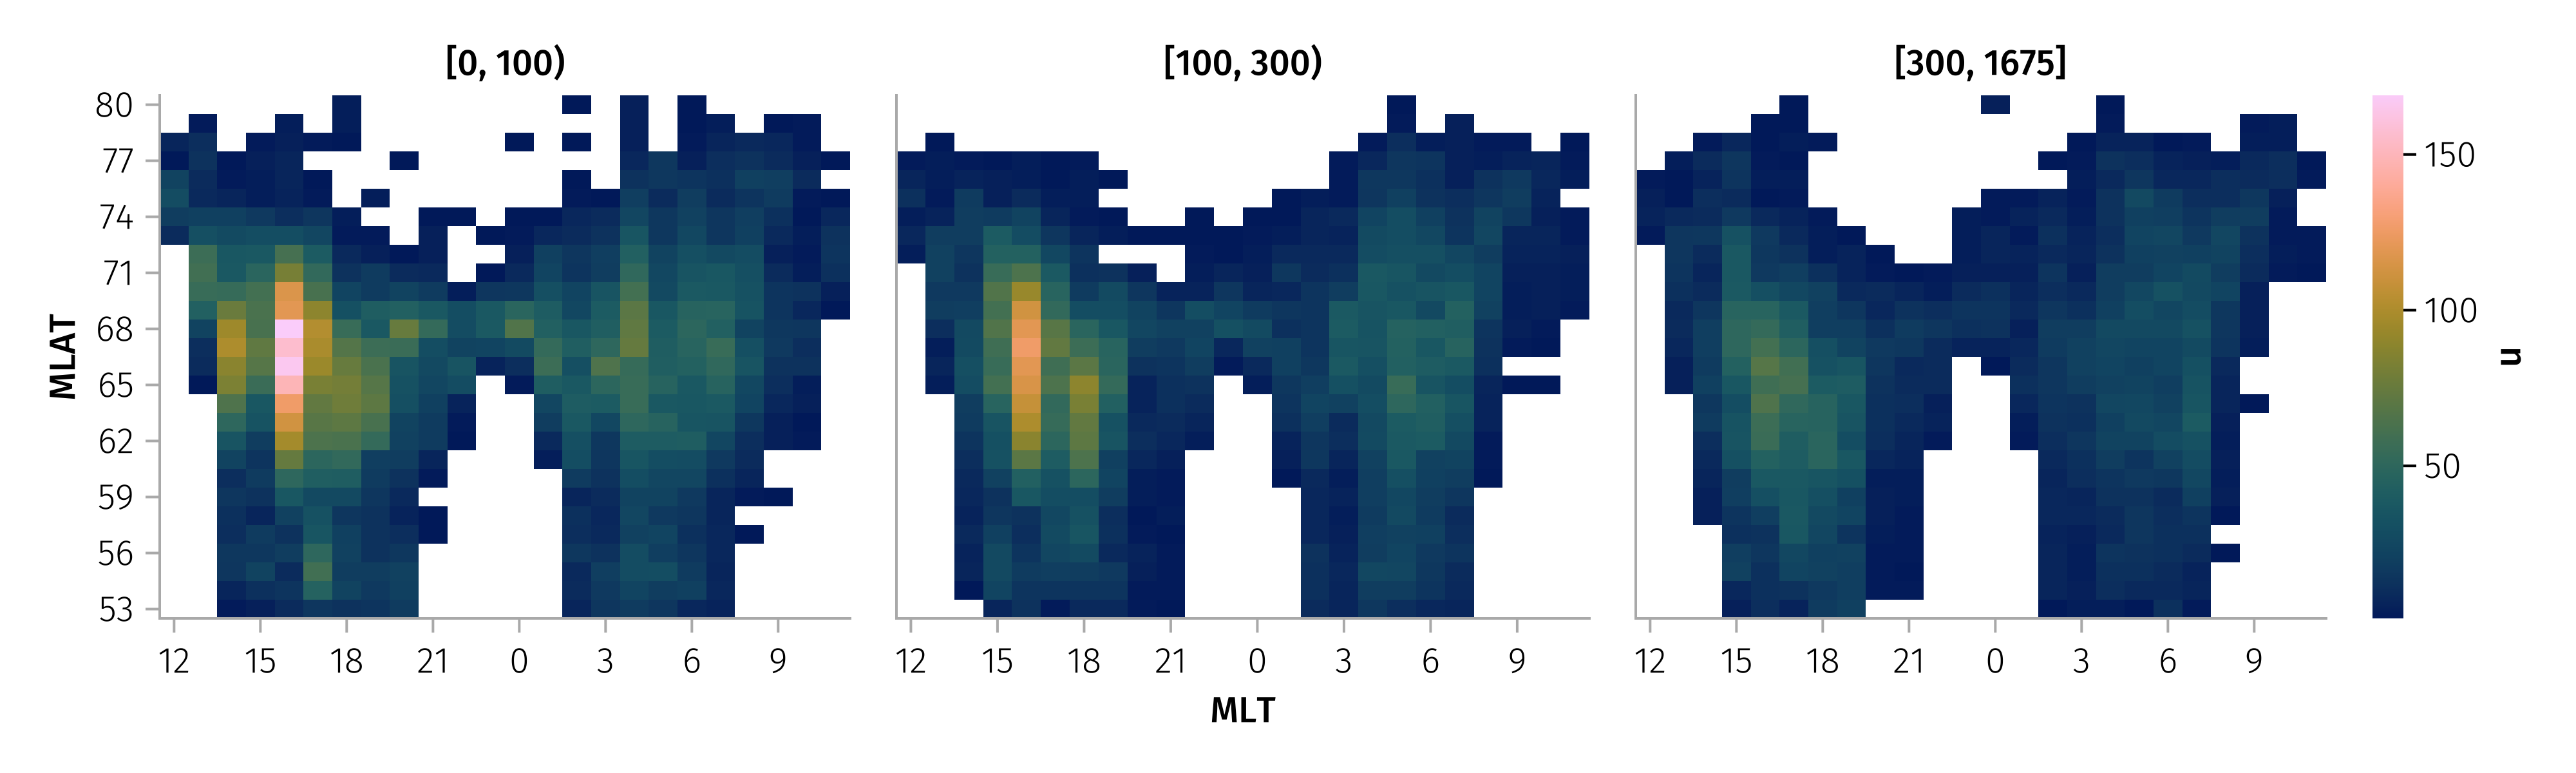

### \* Superposed energy flux analysis

In [0]:
mlt_mlat_ranges = [((2, 4), (70, 72)), ((6, 8), (68, 70)), ((6, 8), (61, 63)), ((12, 14), (62, 64)), ((16, 18), (65.5, 67.5))]
f = Figure(size=(1000, 1200))
E_grid = 10 .^ range(log10(0.03), log10(300), length=200)
for (i, (mlt_range, mlat_range)) in enumerate(mlt_mlat_ranges)
    axs = plot_superposed_spectra!(f[i, 1], sdf, E_grid; mlt_range, mlat_range, n_sample=250)
    i != length(mlt_mlat_ranges) && hidexdecorations!.(axs; ticklabels=false, ticks=false)
end
rowgap!(f.layout, 2)
easy_save("energy_spectra_mlt_mlat")

<figure>
<embed src="attachment:../figures/energy_spectra_mlt_mlat.pdf" />
<figcaption aria-hidden="true">energy_spectra_mlt_mlat</figcaption>
</figure>

### Model parameters variation

In [0]:
f = Figure(; size=(1500, 700))
tdf_spatial = combine(gdf, _variable.(vars) .=> mean, renamecols=false) |> dropmissing!
plot_params_variation(f, tdf_spatial, vars)
easy_save("params_mlt_mlat_mean")

f = Figure(; size=(1500, 700))
tdf_spatial = combine(gdf, _variable.(vars) .=> median, renamecols=false) |> dropmissing!
plot_params_variation(f, tdf_spatial, vars)
easy_save("params_mlt_mlat_median")

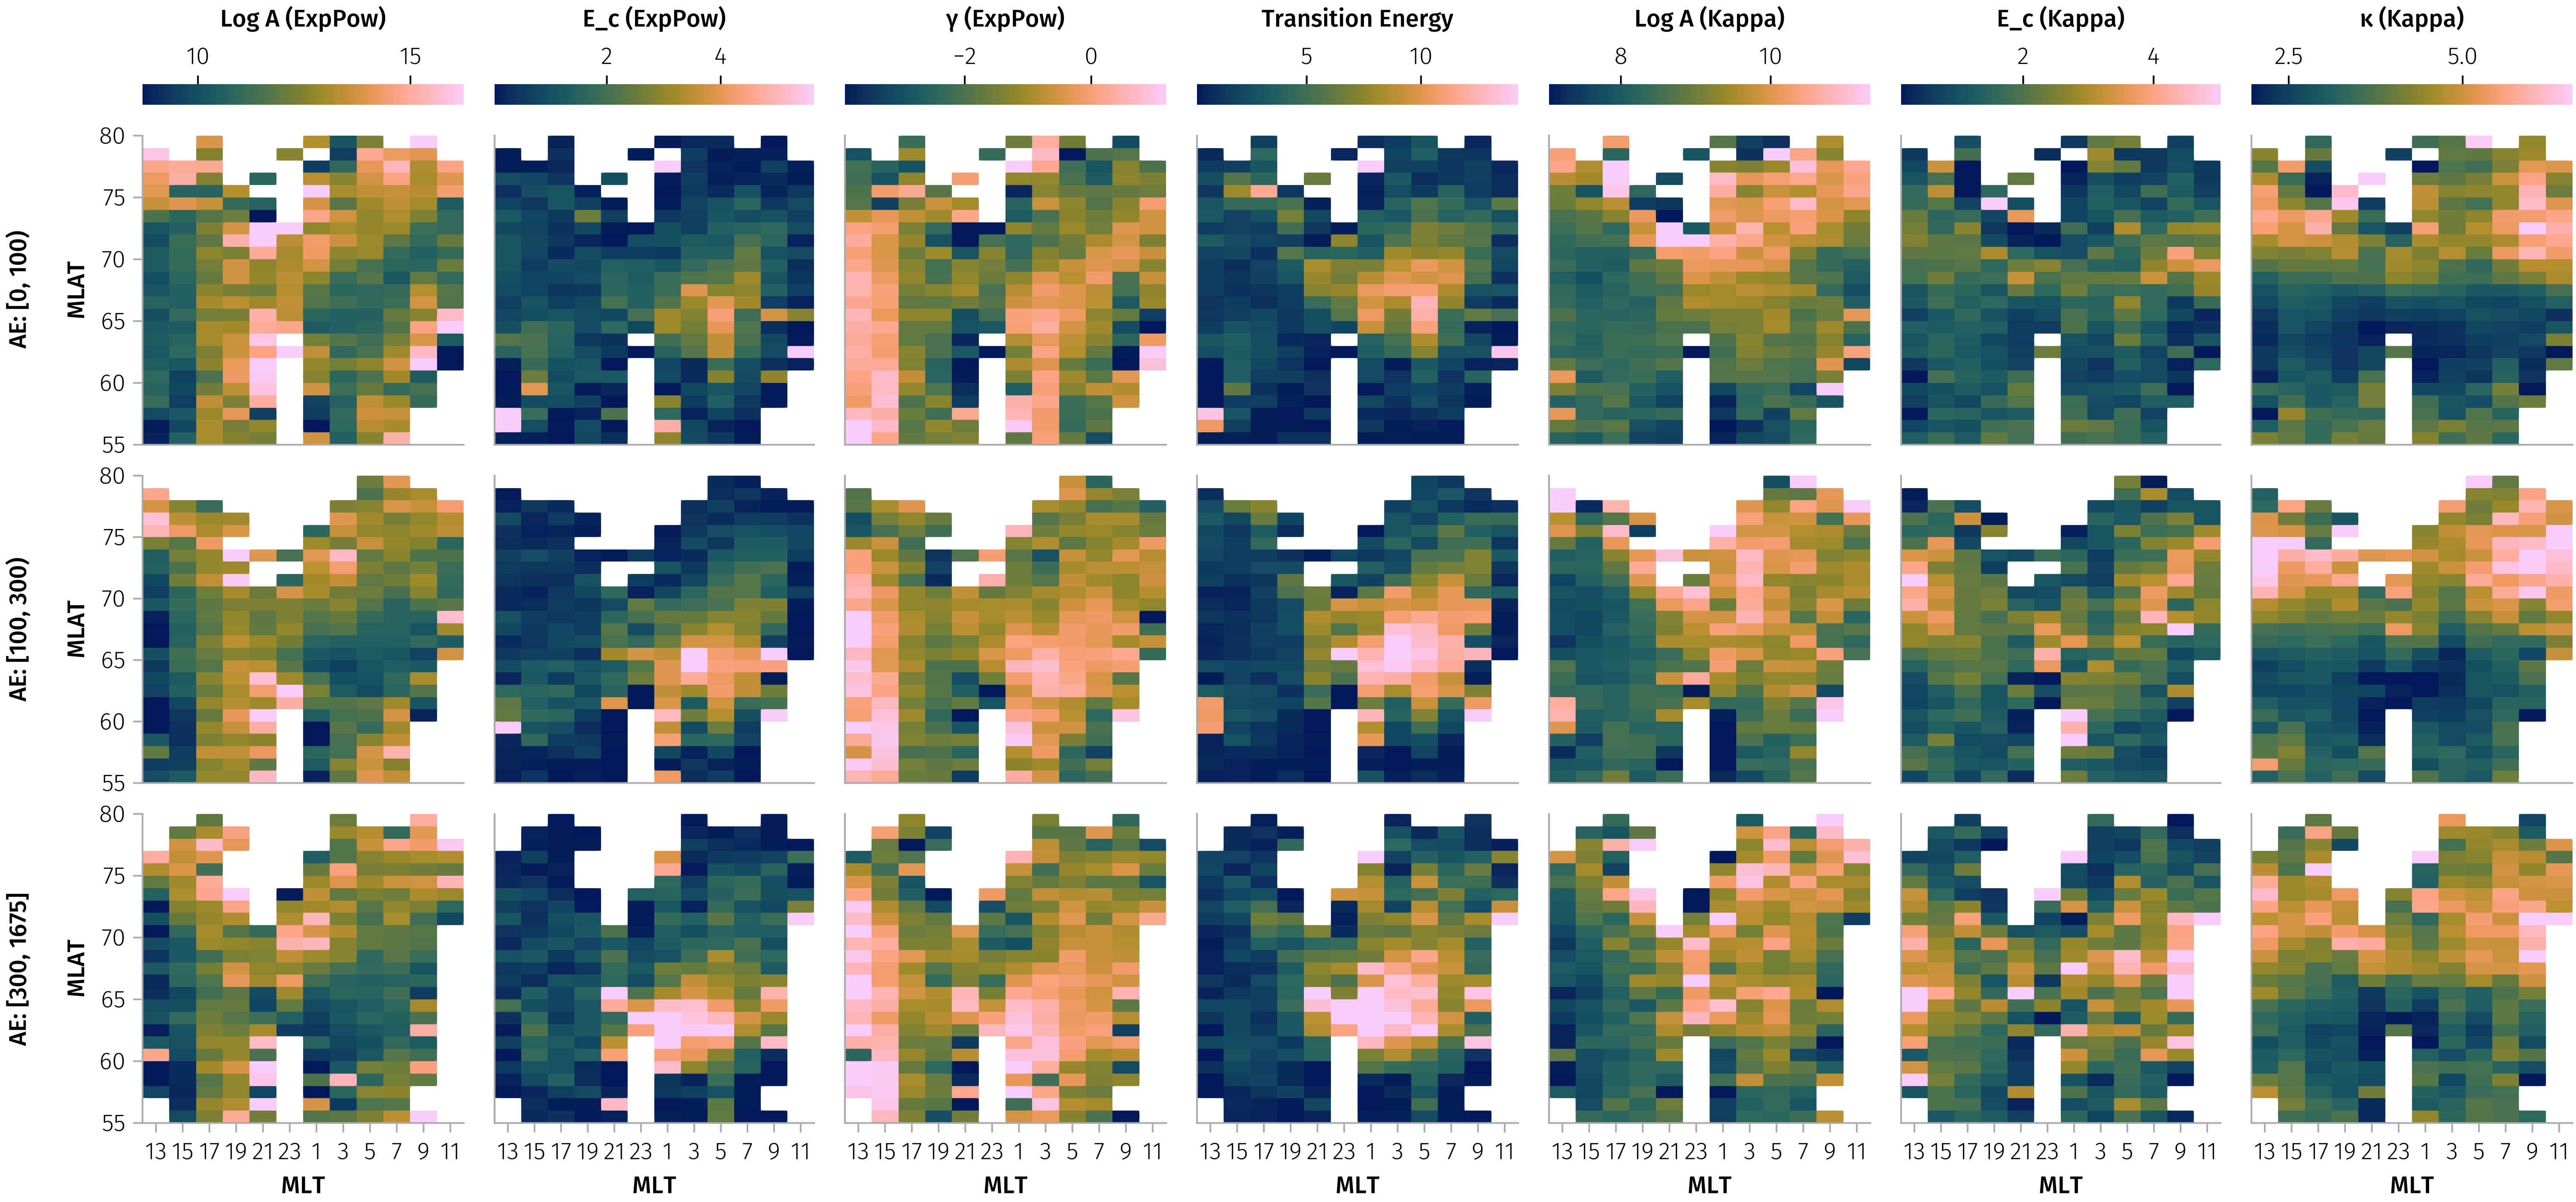 See also [params_mlt_mlat_median.png](../figures/params_mlt_mlat_median.png)

## \* Total number flux and energy flux variation

In [0]:
J_vars = [:J1 => "(a) Number flux (ExpPow)", :J2 => "(b) Number flux (Kappa)", :JE1 => "(c) Energy flux (ExpPow)", :JE2 => "(d) Energy flux (Kappa)"]
let vars = J_vars
    f = Figure(; size=(1200, 700))
    df = combine(gdf, _variable.(vars) .=> mean, renamecols=false) |> dropmissing!
    plot_params_variation(f, df, vars; colorranges=(; JE1=(1e10, 2.6e11), JE2=(1e10, 2.6e11)))
    easy_save("flux_mlt_mlat")
end

In [0]:
for func in (median, mean)
    let vars = [:J2 => L"(a) $J_κ$: Number flux (Kappa)", :JE2 => L"(b) $JE_κ$: Energy flux (Kappa)", :R_J2 => L"(c) $J_κ / J_{total}$", :R_JE2 => L"(d) $JE_κ / JE_{total}$"]
        f = Figure(; size=(1000, 700))
        df = combine(gdf, _variable.(vars) .=> func, renamecols=false) |> dropmissing!
        plot_params_variation(f, df, vars; colorranges=(; JE1=(1e10, 2.6e11), JE2=(1e10, 2.6e11)))
        display(f)
        easy_save("flux_ratio_mlt_mlat_$(func)")
    end
end

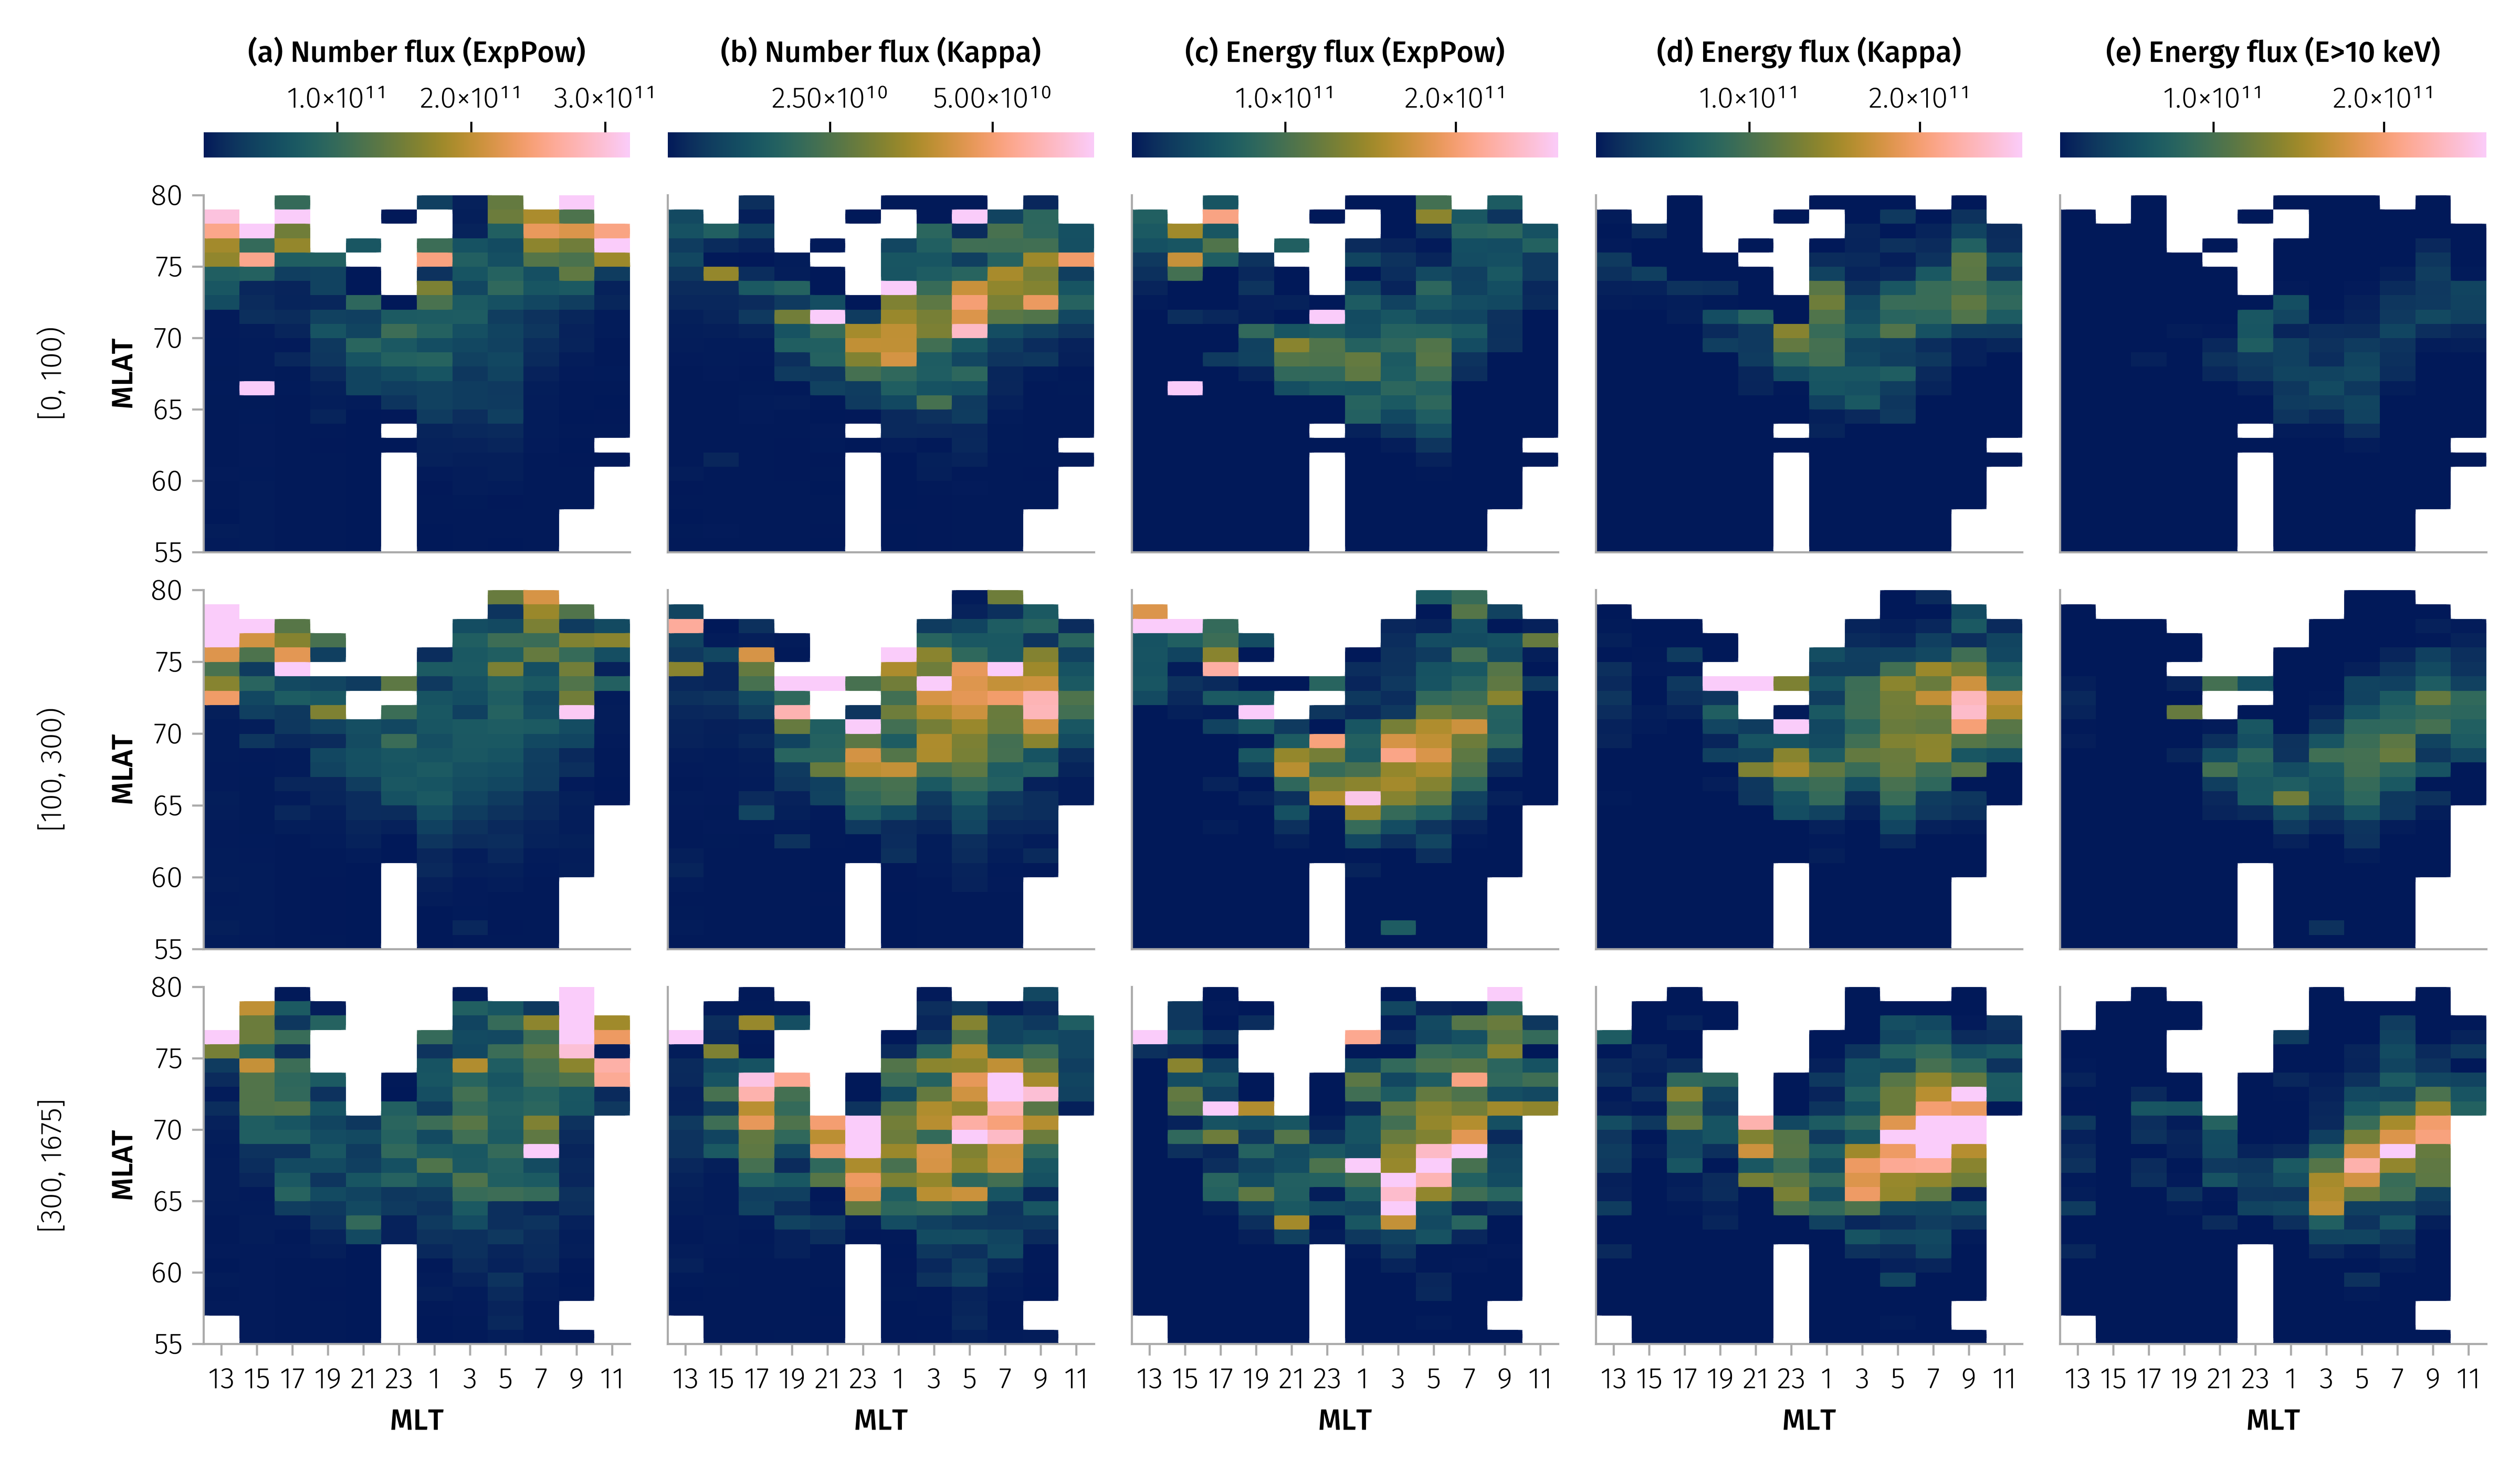
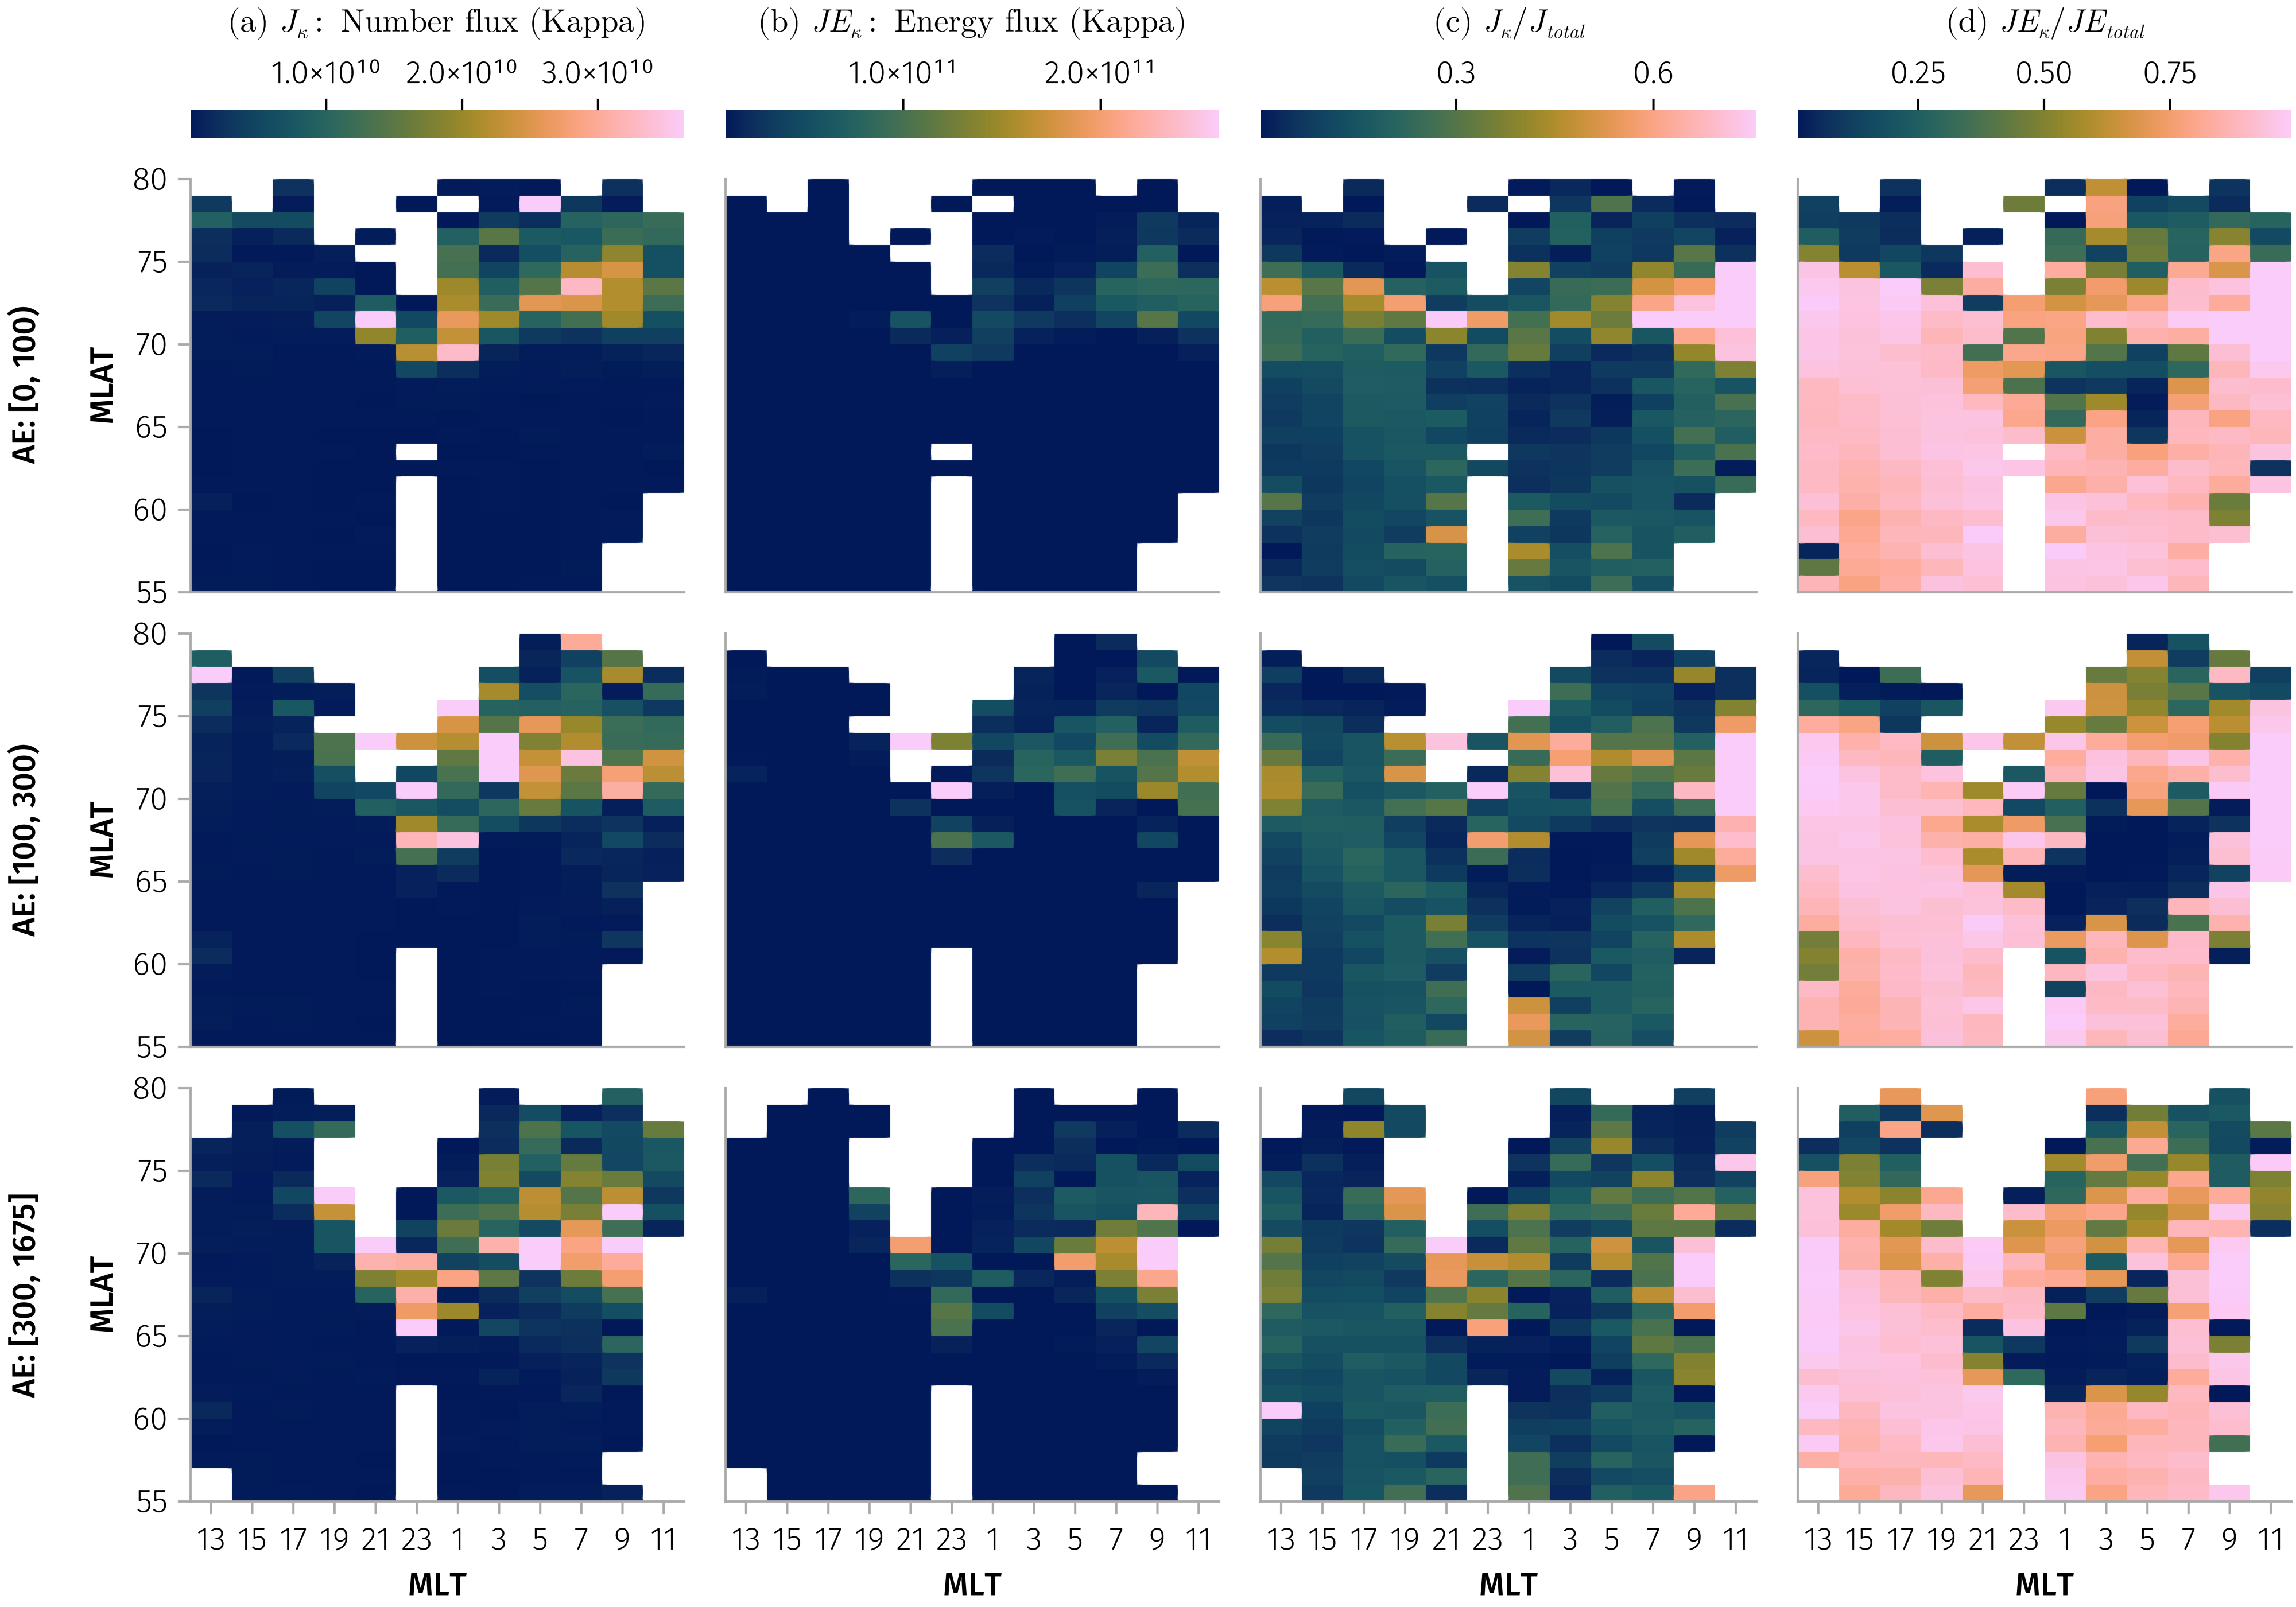

Since in fitting, the parameters are not independent, we check the most probable values of parameter for each models.

In [0]:
using FHist

model1s = m1.(df.model)
model2s = m2.(df.model)

function auto_bins(ary; nbins=nothing)
    nbins = @something nbins FHist._sturges(ary)
    lo, hi = quantile(ary, [0.05, 0.95])
    StatsBase.histrange(lo, hi, nbins)
end

@inline function HistFunc(n)
    @assert n in (1, 2, 3)
    n == 1 && return Hist1D
    n == 2 && return Hist2D
    n == 3 && return Hist3D
end

function most_likely_params(arrs...)
    binedges = auto_bins.(arrs)
    h = HistFunc(length(arrs))(arrs; binedges)
    idxs = argmax(h.bincounts)
    getindex.(h.binedges, Tuple(idxs))
end

function most_likely_params(df, vars)
    arrs = getproperty.(Ref(df), vars)
    most_likely_params(arrs...)
end

most_likely_params(sdf, (:log_A2, :E_c2, :κ))

tdf_most_likely = let
    @chain gdf begin
        combine(
            [:log_A1, :E_c1, :γ] => most_likely_params => :model1,
            [:log_A2, :E_c2, :κ] => most_likely_params => :model2,
            :Emin => most_likely_params => :Emin,
        )
        @rtransform(
            :Emin = :Emin[1],
            :log_A1 = :model1[1],
            :E_c1 = :model1[2],
            :γ = :model1[3],
            :log_A2 = :model2[1],
            :E_c2 = :model2[2],
            :κ = :model2[3],
        )
        dropmissing!
    end
end

# plot_params_variation(f, tdf_most_likely, vars)
# easy_save("params_mlt_mlat_most_likely")

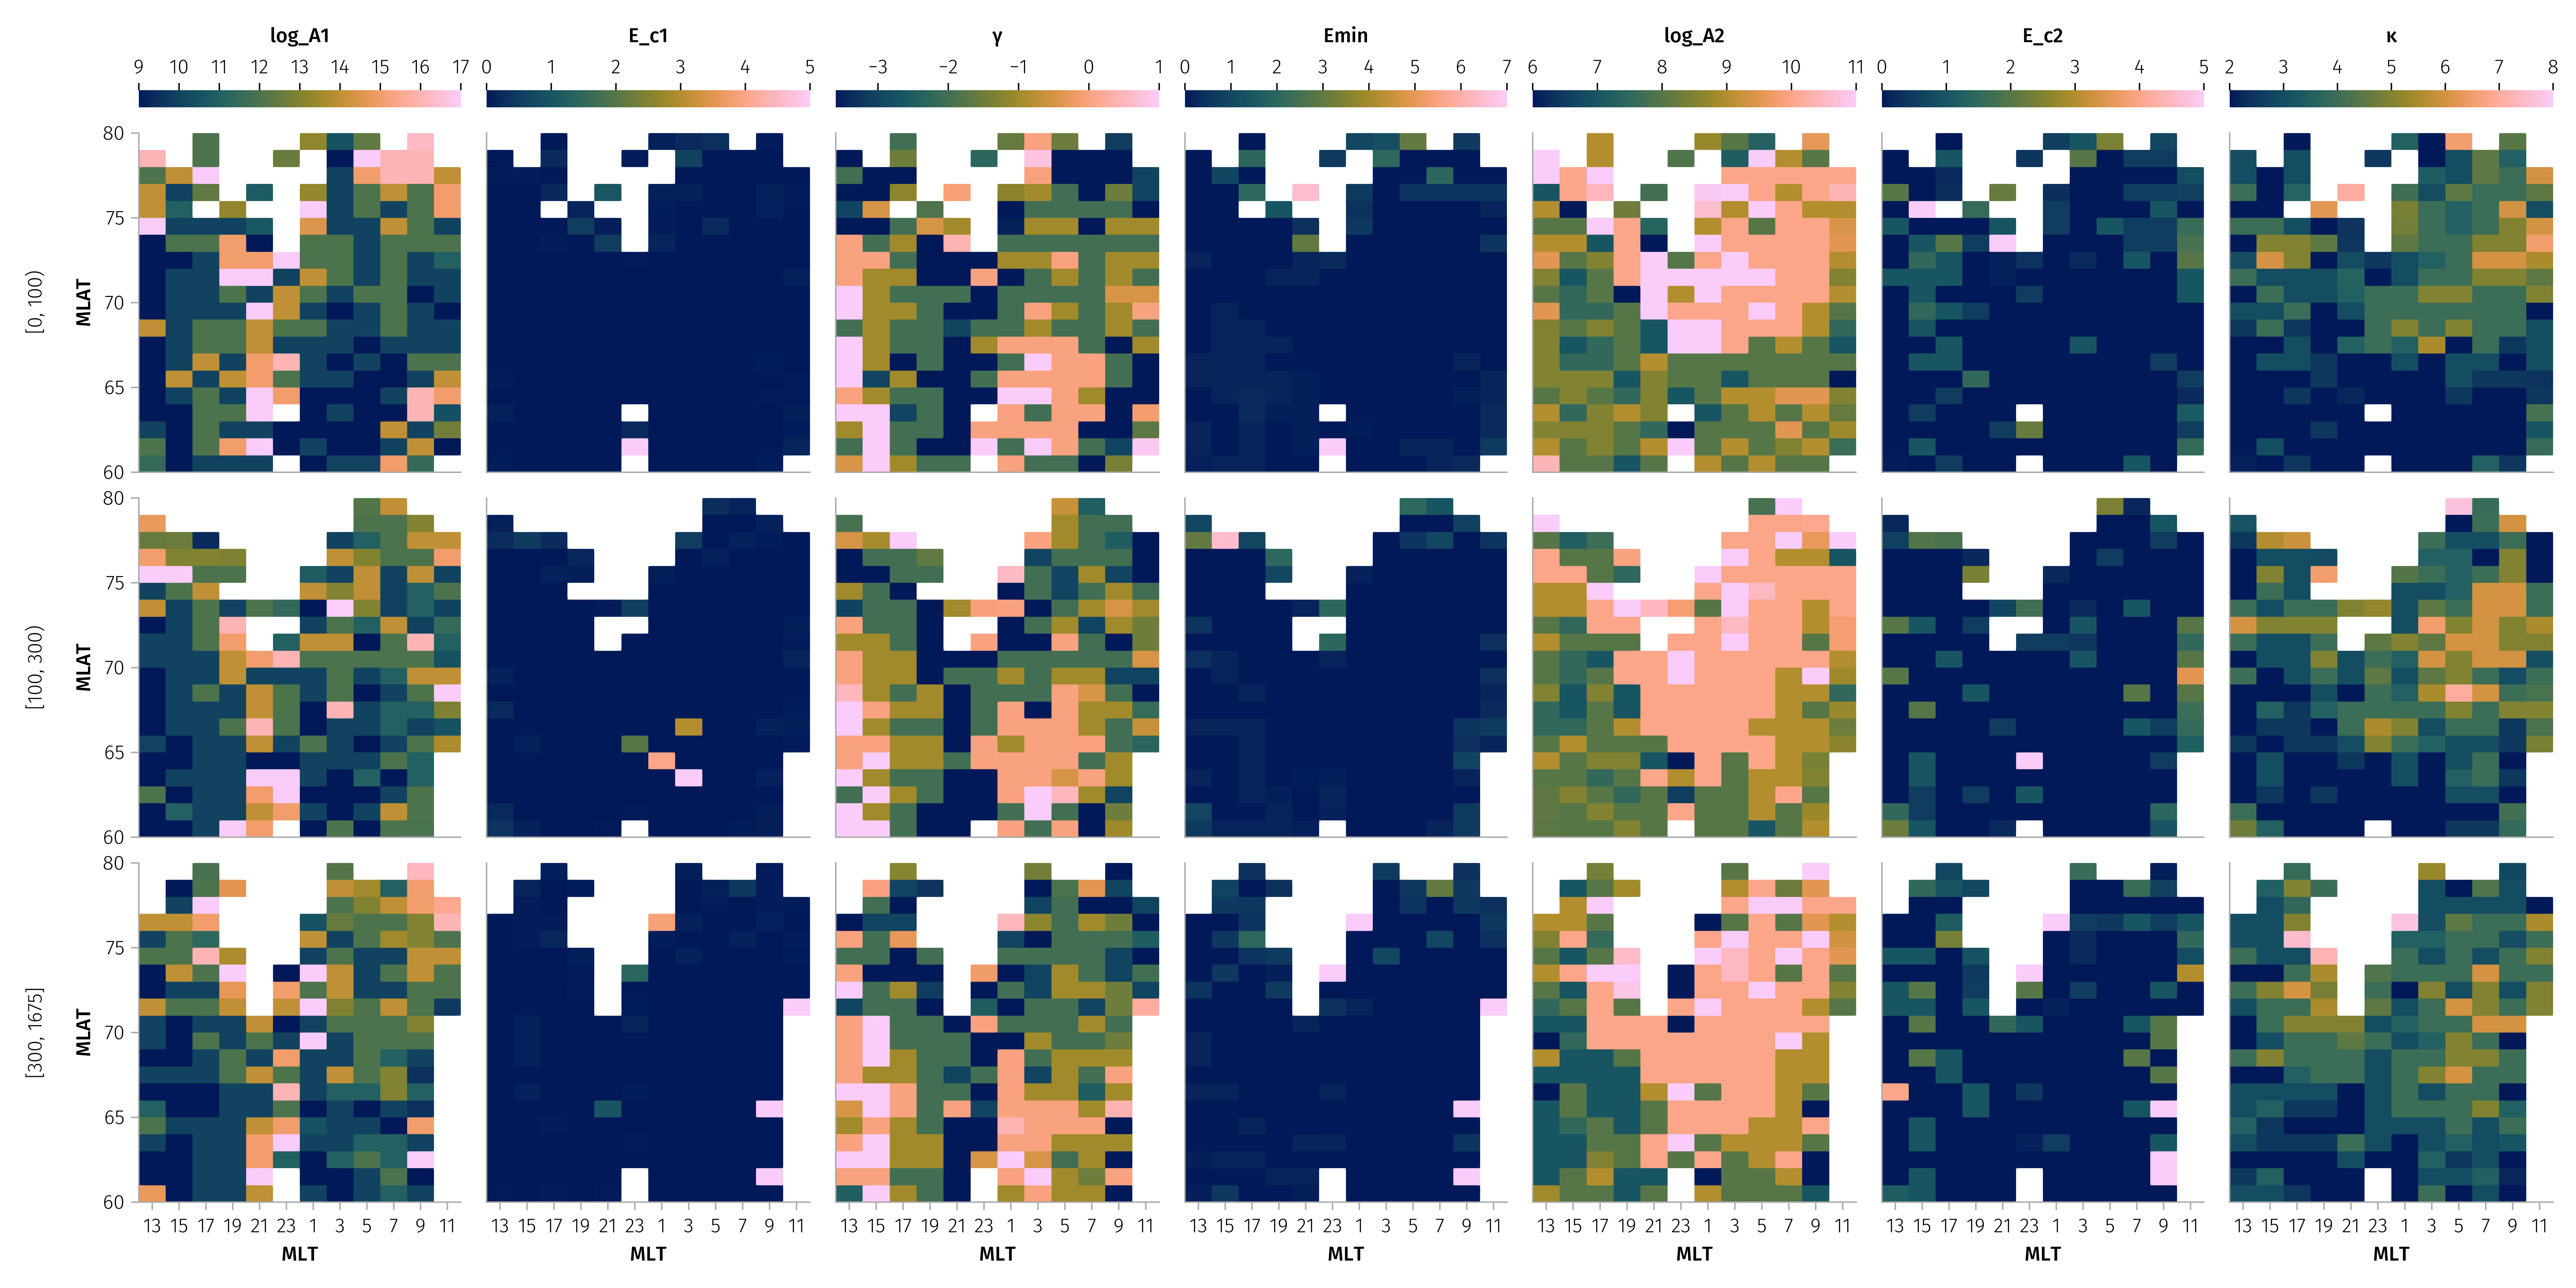

### Fitting of probability distributions

#### Empirical pdf for `log_A1`

In [0]:
using StatsBase
using FHist
includet("../src/statmodel.jl")
# logA1_empirical = empirical_conditional_density(sdf, :log_A1)
var_edges = map(vars) do var
    edge_min, edge_max = quantile(sdf[!, var], [0.01, 0.99])
    range(edge_min, edge_max; length=31)
end

_maximum(h) = maximum(h.weights)
_maximum(h::Hist1D) = maximum(h.bincounts)

hist_funcs = HistFunc.(var_edges)

tdf = @chain gdf begin
    combine(vars .=> hist_funcs, renamecols=false)
    dropmissing!
end

#### Visualizing the empirical pdf

In [0]:
f = Figure(size=(1200, 900))

mlt_idxs = 1:2:12

plot_empirical_conditional_density(f, tdf, vars; mlt_idxs)
# easy_save("empirical_pdf")
f

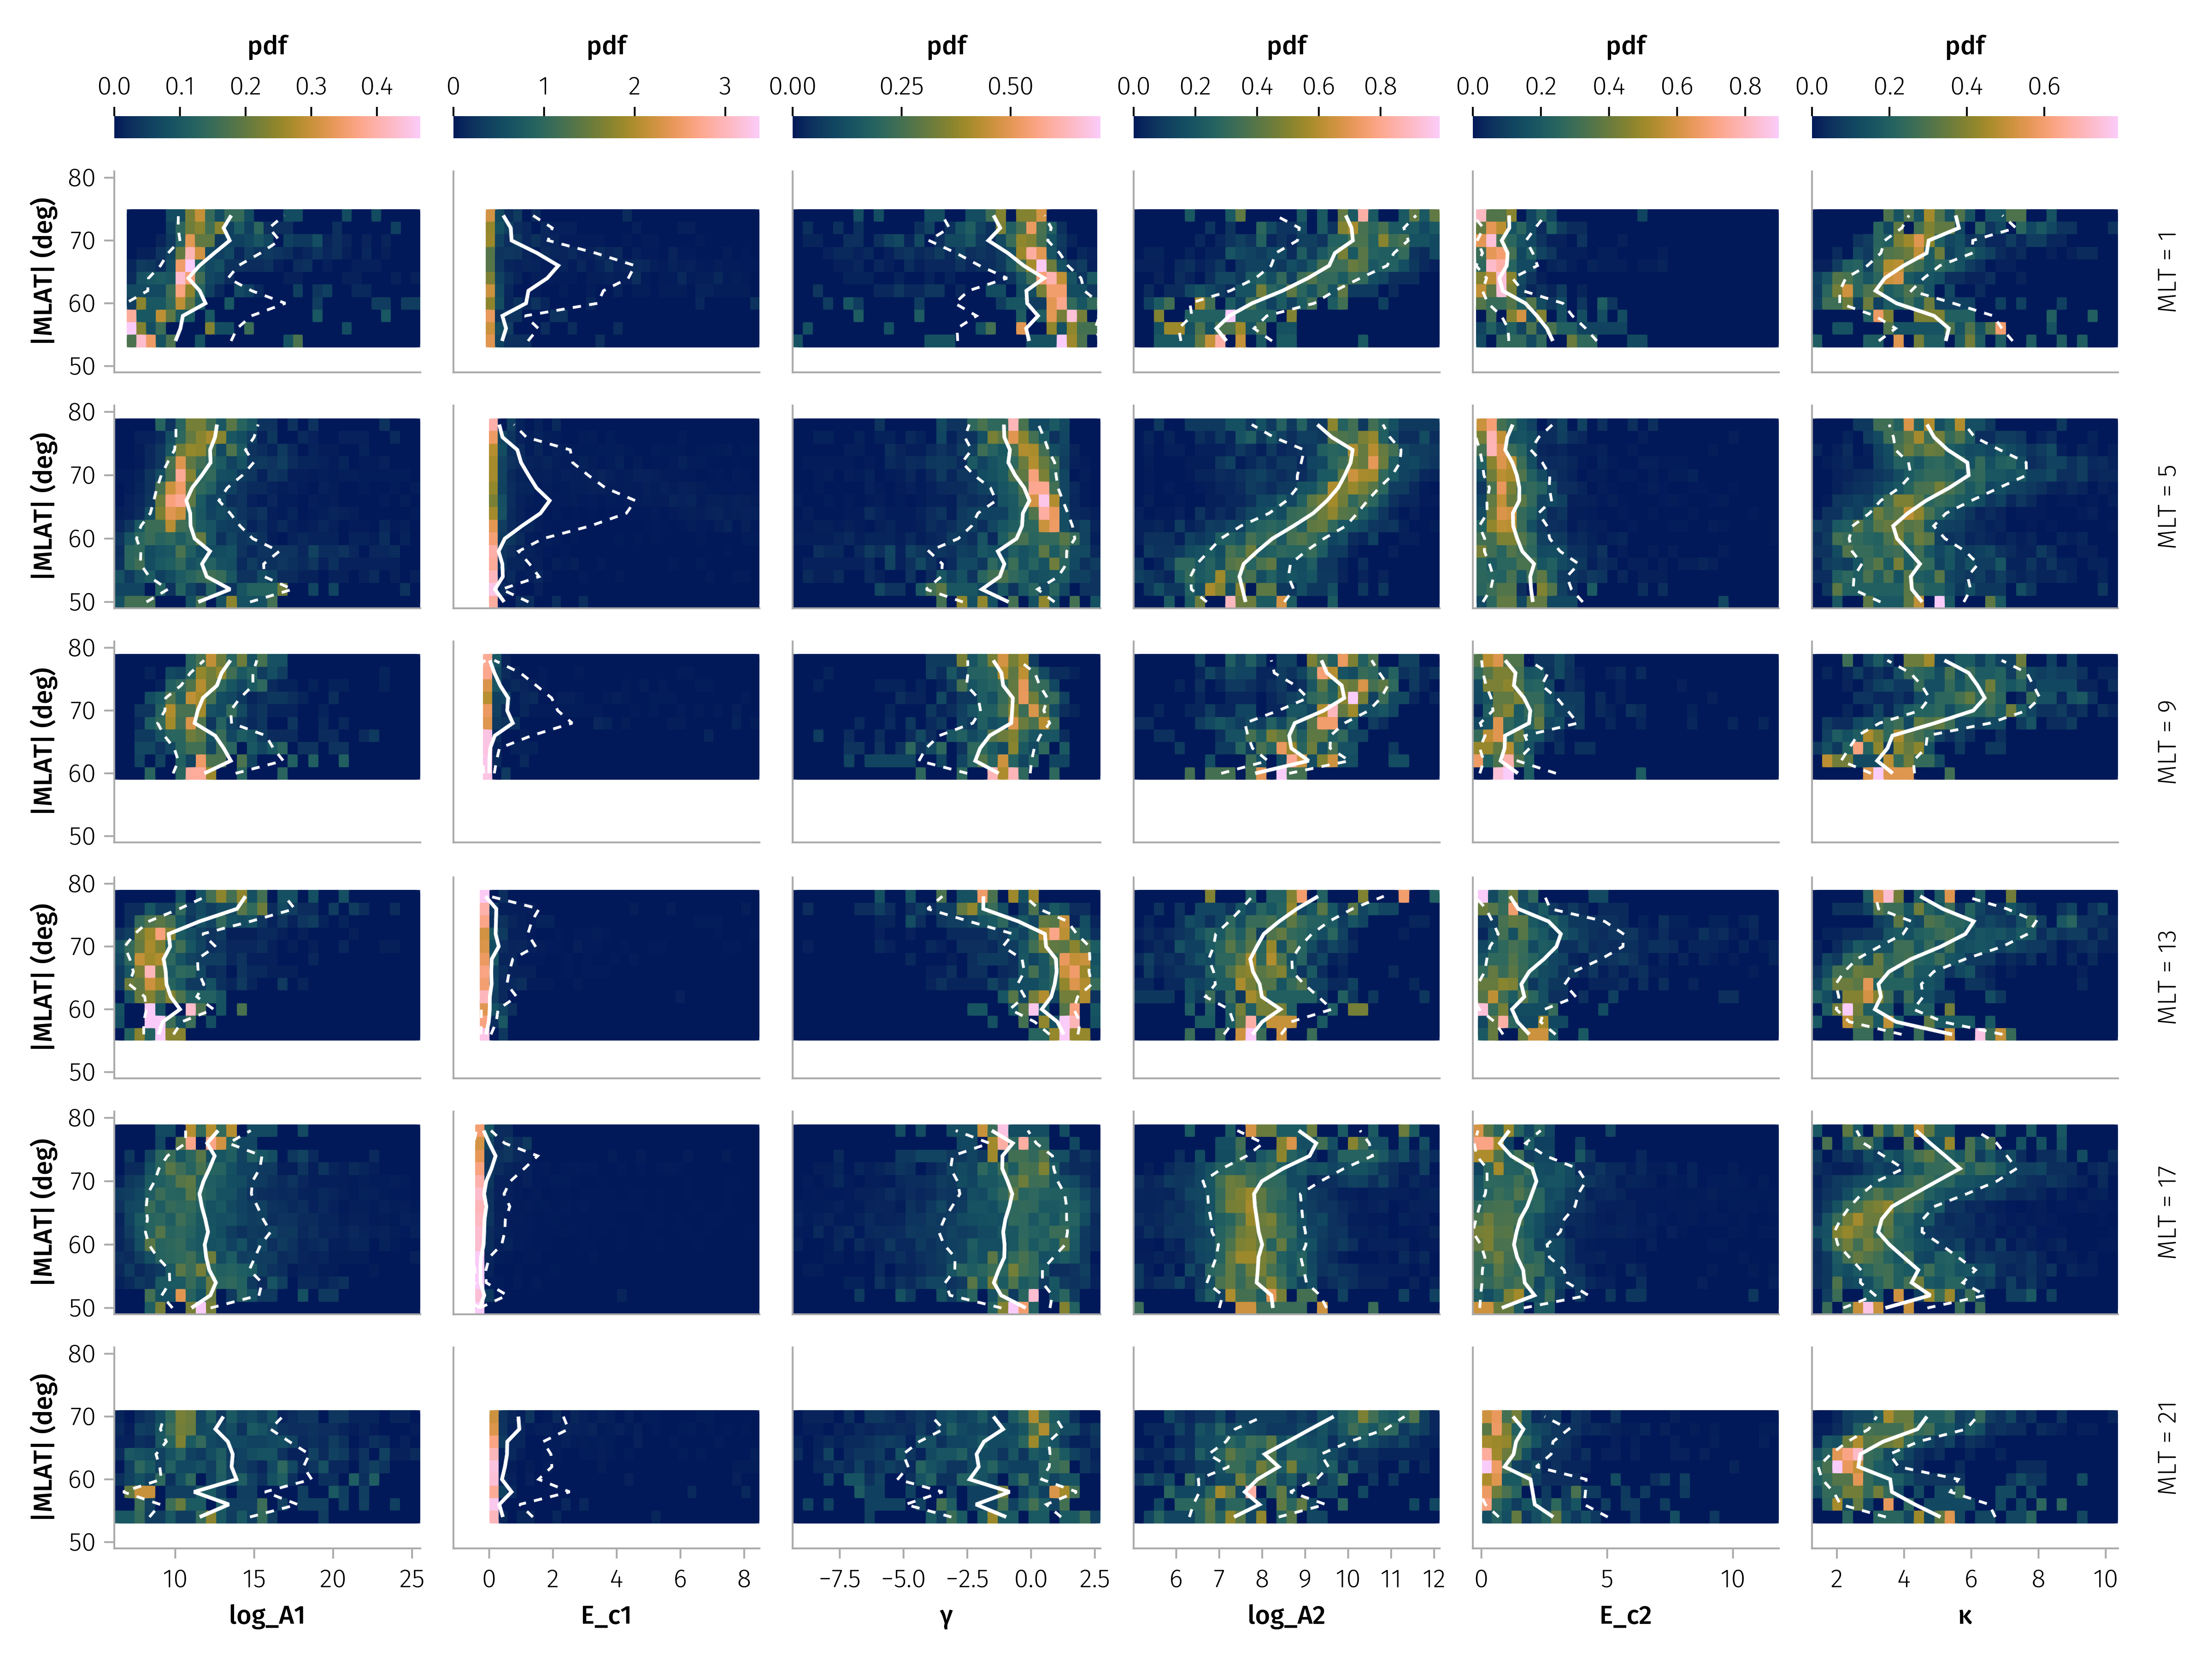

In [0]:
using Measurements

# Fix for AlgebraOfGraphics
# Base.typemin(x::Type{Measurement{Float64}}) = -Inf
# Base.typemax(x::Type{Measurement{Float64}}) = Inf

mean_std(x) = mean(x) ± std(x)

let binedges = 5:15:200
    tdf = @chain sdf begin
        @transform(:maxAE_bin = cut(:maxAE, binedges; extend=missing))
        @groupby(:maxAE_bin)
        combine(vars .=> mean_std, :maxAE => mean; renamecols=false)
        dropmissing!
    end

    # https://github.com/MakieOrg/AlgebraOfGraphics.jl/issues/688
    # AoG does not support Errorbars
    # plt = data(tdf) * mapping(:maxAE, [:log_A1, :E_c1, :γ, :log_A2, :E_c2, :κ]) *
    #   (visual(Scatter) + visual(Errorbars, whiskerwidth=8)) * mapping(layout=AoG.dims(1))
    # draw(plt)

    f = Figure()
    x = tdf.maxAE
    ys = vars .=> ["log A1", "E_c (keV)", "γ", "Emin", "log A2", "E_c2 (keV)", "κ"]
    layouts = [(1, 1), (2, 1), (3, 1), (4, 1), (1, 2), (2, 2), (3, 2)]

    axs = map(layouts, ys) do (i, j), (var, ylabel)
        ax = Axis(f[i, j]; ylabel)
        y = tdf[!, var]
        scatter!(ax, x, y)
        errorbars!(ax, x, y, whiskerwidth=8)
        i != 3 && hidexdecorations!(ax)
        ax
    end
    f
end

### Joint probability distributions

Probability distributions of observations in (Mlat, Ec) and (Mlat, gamma) spaces?

In [0]:
includet("../src/statplot.jl")
using PairPlots, AlgebraOfGraphics
using StatsBase
const AoG = AlgebraOfGraphics

E_c1(model) = E_c(m1_len(model))
E_c2(model) = E_c(m2_len(model))

# plot_parameter_distributions_aog(df; normalization=:pdf)
# plot_parameter_distributions_aog(df; normalization=:column)

# plot_parameter_distributions_aog(df, :mlat; normalization=:column)
plot_parameter_distributions_aog(dropmissing(df), :maxAE; normalization=:pdf, x_binedges=(0:20:400))
# plot_parameter_distributions_aog(dropmissing(df), :maxAE; normalization=:column, x_binedges=(0:20:1000))


In [0]:
# Use PairPlots for comprehensive parameter analysis
function plot_parameter_pairplots(df)
    # Create analysis DataFrame with all relevant parameters
    plot_df = DataFrame(
        mlat=df.mlat,
        E_c=E_c.(m1_len.(df.model)),
        γ=γ_len.(m1_len.(df.model)),
        κ=κ_len.(m2_len.(df.model)),
        success=df.success,
        Δmlt=df.Δmlt
    )

    # Filter for successful fits
    successful_df = @subset(plot_df, :success)

    if nrow(successful_df) == 0
        println("No successful fits found for plotting")
        return nothing
    end

    # Create comprehensive pair plot with all parameters
    return pairplot(successful_df[:, [:mlat, :E_c, :γ, :κ, :Δmlt]])
end

# Plot comprehensive pairwise analysis
plot_parameter_pairplots(df)

In [0]:
# Advanced AlgebraOfGraphics visualization with faceting and grouping
function plot_advanced_parameter_analysis(df)
    # Create comprehensive analysis DataFrame
    plot_df = DataFrame(
        mlat=df.mlat,
        E_c=E_c.(m1_len.(df.model)),
        γ=γ_len.(m1_len.(df.model)),
        κ=κ_len.(m2_len.(df.model)),
        success=df.success,
        Δmlt=df.Δmlt,
        id=df.id,
        # Create MLAT bins for grouping
        mlat_bin=cut(df.mlat, 5, labels=["High", "Mid-High", "Mid", "Mid-Low", "Low"])
    )

    # Filter for successful fits
    successful_df = @subset(plot_df, :success)

    if nrow(successful_df) == 0
        println("No successful fits found for plotting")
        return nothing
    end

    # Create multi-faceted analysis
    base = data(successful_df)

    # Density plots with grouping by DMSP satellite ID
    density_analysis = base *
                       mapping(:mlat => "MLAT (degrees)", :E_c => "E_c (keV)",
                           color=:id => nonnumeric, layout=:id => nonnumeric) *
                       (density() * visual(alpha=0.7) +
                        smooth() * visual(linewidth=2))

    # Scatter plot with trend analysis
    scatter_analysis = base *
                       mapping(:γ => "γ", :E_c => "E_c (keV)",
                           color=:mlat_bin => "MLAT Region",
                           markersize=:Δmlt => "ΔMLT") *
                       (visual(Scatter, alpha=0.7) +
                        smooth() * visual(linewidth=1.5))

    # Create figure with multiple panels
    f = Figure(size=(1600, 1000))

    # Panel 1: Density analysis by satellite
    draw!(f[1, :], density_analysis;
        axis=(title="E_c vs MLAT by DMSP Satellite",
            subtitle="Density distributions with trend lines"))

    # Panel 2: Parameter correlation analysis  
    draw!(f[2, 1], scatter_analysis;
        axis=(title="Parameter Correlations",
            subtitle="E_c vs γ colored by MLAT region, sized by ΔMLT"))

    # Panel 3: Distribution summary
    hist_plot = base *
                mapping(:E_c => "E_c (keV)", layout=:mlat_bin => nonnumeric) *
                histogram(bins=15) * visual(alpha=0.8, color=:steelblue)

    draw!(f[2, 2], hist_plot;
        axis=(title="E_c Distribution by MLAT Region",))

    return f
end

# Create advanced multi-panel analysis
plot_advanced_parameter_analysis(df)

In [0]:
# Statistical summary of the distributions
function summarize_parameter_distributions(df)
    successful_df = @subset(df, :success)

    println("=== Parameter Distribution Summary ===")
    println("Total successful fits: $(nrow(successful_df))")
    println("Total observations: $(nrow(df))")
    println("Success rate: $(round(nrow(successful_df)/nrow(df)*100, digits=2))%")
    println()

    # MLAT statistics
    println("MLAT Statistics:")
    println("  Range: $(round(minimum(successful_df.mlat), digits=2))° to $(round(maximum(successful_df.mlat), digits=2))°")
    println("  Mean: $(round(mean(successful_df.mlat), digits=2))°")
    println("  Std: $(round(std(successful_df.mlat), digits=2))°")
    println()

    # E_c statistics
    E_c_values = [row.model2.E_c for row in eachrow(successful_df) if haskey(row.model2, :E_c)]
    if !isempty(E_c_values)
        println("E_c Statistics:")
        println("  Range: $(round(minimum(E_c_values), digits=2)) to $(round(maximum(E_c_values), digits=2)) keV")
        println("  Mean: $(round(mean(E_c_values), digits=2)) keV")
        println("  Std: $(round(std(E_c_values), digits=2)) keV")
        println("  Median: $(round(median(E_c_values), digits=2)) keV")
        println()
    end

    # γ statistics
    gamma_values = [row.model1.γ for row in eachrow(successful_df) if haskey(row.model1, :γ)]
    if !isempty(gamma_values)
        println("γ Statistics:")
        println("  Range: $(round(minimum(gamma_values), digits=2)) to $(round(maximum(gamma_values), digits=2))")
        println("  Mean: $(round(mean(gamma_values), digits=2))")
        println("  Std: $(round(std(gamma_values), digits=2))")
        println("  Median: $(round(median(gamma_values), digits=2))")
    end
end

# Print statistical summary
summarize_parameter_distributions(df)

## Parameter Statistics and Correlations

``` julia
#TODO: update this part
# Calculate parameter statistics and correlations
using Statistics

# Create summary statistics
param_stats = (
    plec_A_mean=mean([p.plec_A for p in param_analysis]),
    plec_A_std=std([p.plec_A for p in param_analysis]),
    plec_γ_mean=mean([p.plec_γ for p in param_analysis]),
    plec_γ_std=std([p.plec_γ for p in param_analysis]),
    plec_E_c_mean=mean([p.plec_E_c for p in param_analysis]),
    plec_E_c_std=std([p.plec_E_c for p in param_analysis]),
    sbpl_A_mean=mean([p.sbpl_A for p in param_analysis]),
    sbpl_A_std=std([p.sbpl_A for p in param_analysis]),
    sbpl_γ1_mean=mean([p.sbpl_γ1 for p in param_analysis]),
    sbpl_γ1_std=std([p.sbpl_γ1 for p in param_analysis]),
    sbpl_γ2_mean=mean([p.sbpl_γ2 for p in param_analysis]),
    sbpl_γ2_std=std([p.sbpl_γ2 for p in param_analysis]),
    sbpl_Eb_mean=mean([p.sbpl_Eb for p in param_analysis]),
    sbpl_Eb_std=std([p.sbpl_Eb for p in param_analysis])
)

@info "Parameter Statistics:" param_stats

# Create correlation plot between key parameters
f_corr = Figure(size=(1200, 900))

# PowerLawExpCutoff γ vs E_c
ax_corr1 = Axis(f_corr[1, 1], xlabel="Power Index γ (PowerLawExpCutoff)",
    ylabel="Cutoff Energy E_c (keV)", yscale=log10,
    title="PowerLawExpCutoff: γ vs E_c")
scatter!(ax_corr1, [p.plec_γ for p in param_analysis],
    [p.plec_E_c for p in param_analysis],
    color=mlats_all, colormap=:viridis, markersize=8)

# PowerLawExpCutoff A vs γ  
ax_corr2 = Axis(f_corr[1, 2], xlabel="Amplitude A (PowerLawExpCutoff)",
    ylabel="Power Index γ", xscale=log10,
    title="PowerLawExpCutoff: A vs γ")
scatter!(ax_corr2, [p.plec_A for p in param_analysis],
    [p.plec_γ for p in param_analysis],
    color=mlats_all, colormap=:viridis, markersize=8)

# SmoothBrokenPowerlaw γ1 vs γ2
ax_corr3 = Axis(f_corr[2, 1], xlabel="Power Index γ₁ (SBPL)",
    ylabel="Power Index γ₂ (SBPL)",
    title="SmoothBrokenPowerlaw: γ₁ vs γ₂")
scatter!(ax_corr3, [p.sbpl_γ1 for p in param_analysis],
    [p.sbpl_γ2 for p in param_analysis],
    color=mlats_all, colormap=:viridis, markersize=8)

# Break energy vs MLAT colored by PowerLawExpCutoff cutoff
ax_corr4 = Axis(f_corr[2, 2], xlabel="MLAT", ylabel="Break Energy Eb (keV)",
    yscale=log10, title="Break Energy vs MLAT")
scatter!(ax_corr4, mlats_all, [p.sbpl_Eb for p in param_analysis],
    color=[p.plec_E_c for p in param_analysis], colormap=:plasma, markersize=8)

# Add colorbars
Colorbar(f_corr[1:2, 3], colormap=:viridis, colorrange=extrema(mlats_all),
    label="MLAT")

f_corr
```